# <font color = "tomato">ATHENA–CAMM Hackathon | Ternary Spectroscopy
-  Two challenges, one hidden measurement API</font>

**Challenge 1**
    
    Learn to measure a spectrum:** At one fixed composition, choose wavelengths and acquisition durations to reconstruct the complete **512-channel spectrum**.

**Challenge 2**
    
    Explore the whole ternary wafer:** Choose both compositions and wavelengths/time to reconstruct the full **spectral cube** $S(x,y,E)$ across the ternary triangle.

**Scientific objective:** 

    Minimize reconstruction error compared with organizer-only hidden noiseless ground truth. **Phase classification is not the scoring target.** The true phase diagram, true spectra, and noise laws are not visible to participants.

The following baselines are intentionally simple. Replace their acquisition and interpolation strategies with your own. Running the acquisition cells consumes episode budget.

<a href="https://colab.research.google.com/github/kbarakati/athena_camm_hackathon/blob/k4my4r/docs/day_23_10302026/ATHENA_Ternary_Spectroscopy.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>

## 0. Connect to the common HTTPS API

Use the actual URL from the organizers.

In [1]:
import requests
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import griddata
from matplotlib.tri import Triangulation

BASE_URL = "https://athena-spectral-api.onrender.com"  # Replace if organizer provides a different URL
BASE_URL = BASE_URL.rstrip("/")

def api(method, path, payload=None, token=None):
    headers = {"X-Session-ID": token} if token else {}
    response = requests.request(method, BASE_URL + path, json=payload, headers=headers, timeout=120)
    if not response.ok:
        raise RuntimeError(f"{method} {path}: HTTP {response.status_code}: {response.text[:500]}")
    return response.json()

info = api("GET", "/info")
print("Available tasks:", info["tasks"])
print("Single-spectrum budget:", info["time_budget"])
print("Full-wafer budget:", info["cube_time_budget"])
print("Evaluation cube shape:", info["cube_shape"])
energy = np.linspace(*info["wavelength_range"], info["channels"])


Available tasks: ['single-spectrum', 'ternary-spectral-cube']
Single-spectrum budget: 30.0
Full-wafer budget: 900.0
Evaluation cube shape: [120, 512]


# <font color = "plum">**Challenge 1**</font>
    
    Learn to measure a spectrum

## 1. Start an experimental session

In [2]:
episode1 = api(
    "POST",
    "/session",
    {"task": "single-spectrum"}
)

TOKEN1 = episode1["session_id"]

x = info["composition"]["x"]
y = info["composition"]["y"]

print(f"Composition: A={x:.2f}, B={y:.2f}, C={1-x-y:.2f}")
print("Time budget:", episode1["time_budget"])
print("Spectral channels:", len(energy))

Composition: A=0.30, B=0.40, C=0.30
Time budget: 30.0
Spectral channels: 512


## 2. Define measurement functions

In [3]:
def measure1(wavelength, time):
    return api(
        "POST",
        "/pixel",
        {
            "wavelength": float(wavelength),
            "time": float(time)
        },
        TOKEN1
    )

def budget1():
    return api("GET", "/budget", token=TOKEN1)

print(budget1())

{'time_used': 0.0, 'time_remaining': 30.0, 'measurements': 0}


## 3. Baseline: Measure 30 wavelengths

In [4]:
n1 = 30

sample_E1 = np.linspace(
    energy.min(),
    energy.max(),
    n1
)

t1 = episode1["time_budget"] / n1

observations1 = []

for wavelength in sample_E1:
    result = measure1(wavelength, t1)
    observations1.append(result)

measured_E1 = np.array([
    r["wavelength"] for r in observations1
])

measured_I1 = np.array([
    r["intensity"] for r in observations1
])

print("Measurements completed:", len(observations1))
print("Remaining budget:", budget1())

Measurements completed: 30
Remaining budget: {'time_used': 30.0, 'time_remaining': 0.0, 'measurements': 30}


#  GP + Time

In [5]:
import numpy as np
import matplotlib.pyplot as plt

from scipy.linalg import solve_triangular
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import ConstantKernel, Matern

# ============================================================
# 1. Start a NEW session
# ============================================================

episode_gp = api("POST", "/session", {"task": "single-spectrum"})
TOKEN_GP = episode_gp["session_id"]

TOTAL_BUDGET = float(episode_gp["time_budget"])

def measure_gp(E, t):
    return api(
        "POST", "/pixel",
        {"wavelength": float(E), "time": float(t)},
        TOKEN_GP
    )

def check_gp_budget():
    return api("GET", "/budget", token=TOKEN_GP)


# ============================================================
# 2. Configuration
# ============================================================

# Candidate durations: adjust if API constraints require it
TIME_CHOICES = np.array([0.5, 1.0, 2.0, 3.0])

# Initial broad exploration
N_INITIAL = 8
INITIAL_TIME = 0.75

# Repeat 3 initial locations to estimate measurement noise
N_REPEATS = 3

# Evaluate acquisition decisions at these candidate wavelengths
N_CANDIDATES = 160

E_GRID = np.asarray(energy, dtype=float)
E_MIN, E_MAX = E_GRID.min(), E_GRID.max()
E_RANGE = E_MAX - E_MIN

# Scale wavelength to [0, 1] for GP fitting
def normalize_E(E):
    return (np.asarray(E) - E_MIN) / E_RANGE

candidate_E = np.linspace(E_MIN, E_MAX, N_CANDIDATES)

records = []
spent = 0.0


def take_measurement(E, t):
    global spent

    if spent + t > TOTAL_BUDGET + 1e-9:
        raise ValueError("Insufficient measurement budget")

    response = measure_gp(E, t)

    records.append({
        "E": float(response["wavelength"]),
        "intensity": float(response["intensity"]),
        "time": float(t),
    })

    spent += t
    return records[-1]


# ============================================================
# 3. Initial exploration and noise calibration
# ============================================================

seed_E = np.linspace(E_MIN, E_MAX, N_INITIAL)

for E in seed_E:
    take_measurement(E, INITIAL_TIME)

repeat_indices = [1, N_INITIAL // 2, N_INITIAL - 2]

noise_estimates = []

for i in repeat_indices:
    E = seed_E[i]

    original = records[i]
    repeated = take_measurement(E, INITIAL_TIME)

    # Difference of independent observations:
    # Var(y1-y2) = sigma0^2 * (1/t1 + 1/t2)
    difference = original["intensity"] - repeated["intensity"]

    sigma2 = difference**2 / (2.0 / INITIAL_TIME)
    noise_estimates.append(sigma2)

initial_y = np.array([r["intensity"] for r in records])
initial_scale = max(float(np.std(initial_y)), 1e-8)

# Robust estimate, with a small numerical floor
sigma2_unit = max(
    float(np.median(noise_estimates)),
    (0.01 * initial_scale)**2
)

print("Initial measurements:", len(records))
print("Estimated unit-time noise variance:", sigma2_unit)
print("Initial budget consumed:", spent)


# ============================================================
# 4. Fit GP with acquisition-time-dependent noise
# ============================================================

def fit_gp(records):
    X = np.array([r["E"] for r in records])
    y = np.array([r["intensity"] for r in records])
    times = np.array([r["time"] for r in records])

    y_mean = float(np.mean(y))
    y_scale = max(float(np.std(y)), 1e-8)

    X_train = normalize_E(X).reshape(-1, 1)
    y_train = (y - y_mean) / y_scale

    # Heteroscedastic observation variance
    alpha = (sigma2_unit / y_scale**2) / times

    kernel = ConstantKernel(1.0, constant_value_bounds="fixed") * Matern(
        length_scale=0.12,
        length_scale_bounds="fixed",
        nu=1.5
    )

    gp = GaussianProcessRegressor(
        kernel=kernel,
        alpha=alpha,
        optimizer=None,
        normalize_y=False
    )

    gp.fit(X_train, y_train)

    return gp, y_mean, y_scale


# ============================================================
# 5. Optimize wavelength AND acquisition time
# ============================================================

def select_next_measurement(gp, y_scale, remaining):

    available_times = TIME_CHOICES[
        TIME_CHOICES <= remaining + 1e-9
    ]

    if len(available_times) == 0:
        return None

    X_grid = normalize_E(E_GRID).reshape(-1, 1)
    X_cand = normalize_E(candidate_E).reshape(-1, 1)

    kernel = gp.kernel_
    X_train = gp.X_train_

    # Covariance between evaluation grid and candidate wavelengths
    K_grid_cand = kernel(X_grid, X_cand)

    V_grid = solve_triangular(
        gp.L_, kernel(X_train, X_grid), lower=True
    )

    V_cand = solve_triangular(
        gp.L_, kernel(X_train, X_cand), lower=True
    )

    # Current posterior cross-covariance
    posterior_cov = K_grid_cand - V_grid.T @ V_cand

    # Current posterior variance at each candidate
    prior_var = kernel.diag(X_cand)
    posterior_var = np.maximum(
        prior_var - np.sum(V_cand**2, axis=0),
        1e-12
    )

    # Integrated squared covariance across all 512 channels
    integrated_cov2 = np.mean(posterior_cov**2, axis=0)

    # Noise in standardized GP units
    normalized_noise = sigma2_unit / y_scale**2

    best = None
    best_score = -np.inf

    for t in available_times:

        observation_variance = normalized_noise / t

        # Expected reduction in integrated posterior variance
        variance_reduction = integrated_cov2 / (
            posterior_var + observation_variance
        )

        # Information gained per acquisition-time unit
        scores = variance_reduction / t

        j = int(np.argmax(scores))

        if scores[j] > best_score:
            best_score = float(scores[j])
            best = {
                "E": float(candidate_E[j]),
                "time": float(t),
                "score": best_score
            }

    return best


# ============================================================
# 6. Closed-loop autonomous experiment
# ============================================================

history = []

while TOTAL_BUDGET - spent >= TIME_CHOICES.min() - 1e-9:

    gp, y_mean, y_scale = fit_gp(records)

    remaining = TOTAL_BUDGET - spent

    decision = select_next_measurement(
        gp, y_scale, remaining
    )

    if decision is None:
        break

    result = take_measurement(
        decision["E"],
        decision["time"]
    )

    history.append({
        **decision,
        "intensity": result["intensity"],
        "spent": spent
    })

    print(
        f"Step {len(history):02d} | "
        f"E={decision['E']:.3f} | "
        f"t={decision['time']:.2f} | "
        f"Spent={spent:.2f}/{TOTAL_BUDGET:.2f}"
    )


# ============================================================
# 7. Final 512-channel reconstruction
# ============================================================

gp, y_mean, y_scale = fit_gp(records)

X_grid = normalize_E(E_GRID).reshape(-1, 1)

pred_norm, std_norm = gp.predict(
    X_grid, return_std=True
)

predicted_spectrum_gp = pred_norm * y_scale + y_mean
predicted_uncertainty_gp = std_norm * y_scale

print("\nTotal measurements:", len(records))
print("Time used:", spent)
print("Remaining local budget:", TOTAL_BUDGET - spent)
print("Server budget:", check_gp_budget())
print("Reconstructed channels:", len(predicted_spectrum_gp))


Initial measurements: 11
Estimated unit-time noise variance: 0.005237407869054594
Initial budget consumed: 8.25
Step 01 | E=3.585 | t=0.50 | Spent=8.75/30.00
Step 02 | E=6.478 | t=0.50 | Spent=9.25/30.00
Step 03 | E=0.692 | t=0.50 | Spent=9.75/30.00
Step 04 | E=9.308 | t=0.50 | Spent=10.25/30.00
Step 05 | E=4.969 | t=0.50 | Spent=10.75/30.00
Step 06 | E=2.201 | t=0.50 | Spent=11.25/30.00
Step 07 | E=7.799 | t=0.50 | Spent=11.75/30.00
Step 08 | E=3.333 | t=0.50 | Spent=12.25/30.00
Step 09 | E=8.050 | t=0.50 | Spent=12.75/30.00
Step 10 | E=2.013 | t=0.50 | Spent=13.25/30.00
Step 11 | E=6.289 | t=0.50 | Spent=13.75/30.00
Step 12 | E=0.503 | t=0.50 | Spent=14.25/30.00
Step 13 | E=9.497 | t=0.50 | Spent=14.75/30.00
Step 14 | E=4.780 | t=0.50 | Spent=15.25/30.00
Step 15 | E=3.899 | t=0.50 | Spent=15.75/30.00
Step 16 | E=7.484 | t=0.50 | Spent=16.25/30.00
Step 17 | E=5.283 | t=0.50 | Spent=16.75/30.00
Step 18 | E=6.792 | t=0.50 | Spent=17.25/30.00
Step 19 | E=2.516 | t=0.50 | Spent=17.75/30.0

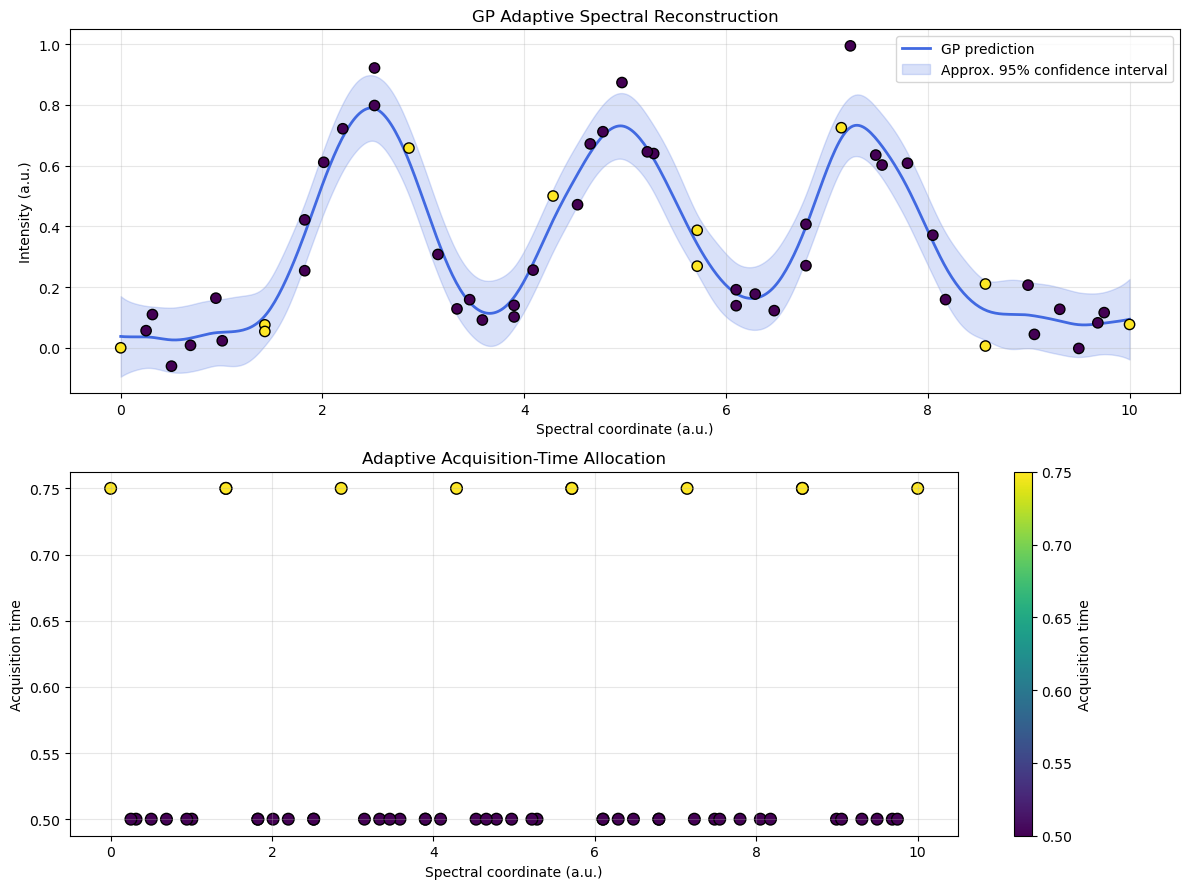

In [8]:
fig, axes = plt.subplots(2, 1, figsize=(12, 9))

# Reconstructed spectrum
ax = axes[0]

ax.plot(
    E_GRID, predicted_spectrum_gp,
    color="royalblue", lw=2,
    label="GP prediction"
)

ax.fill_between(
    E_GRID,
    predicted_spectrum_gp - 1.96 * predicted_uncertainty_gp,
    predicted_spectrum_gp + 1.96 * predicted_uncertainty_gp,
    color="royalblue", alpha=0.2,
    label="Approx. 95% confidence interval"
)

measured_E = np.array([r["E"] for r in records])
measured_I = np.array([r["intensity"] for r in records])
measured_t = np.array([r["time"] for r in records])

ax.scatter(
    measured_E, measured_I,
    c=measured_t,
    cmap="viridis",
    edgecolors="black",
    s=55,
    zorder=3
)

ax.set(
    title="GP Adaptive Spectral Reconstruction",
    xlabel="Spectral coordinate (a.u.)",
    ylabel="Intensity (a.u.)"
)
ax.legend()
ax.grid(alpha=0.3)

# Acquisition-time allocation
ax = axes[1]

sc = ax.scatter(
    measured_E, measured_t,
    c=measured_t,
    cmap="viridis",
    s=70,
    edgecolors="black"
)

ax.set(
    title="Adaptive Acquisition-Time Allocation",
    xlabel="Spectral coordinate (a.u.)",
    ylabel="Acquisition time"
)
ax.grid(alpha=0.3)

plt.colorbar(sc, ax=ax, label="Acquisition time")
plt.tight_layout()
plt.show()


In [10]:
# Submit GP reconstruction for evaluation
submission_gp = {
    "energy": E_GRID.tolist(),
    "predicted_intensity": predicted_spectrum_gp.tolist()
}

result_gp = api("POST", "/submit", submission_gp, TOKEN_GP)

# print("GP Evaluation Results:")
# print(result_gp)
result_gp

RuntimeError: POST /submit: HTTP 403: {"detail":"Episode already submitted"}

# appraoch GP + Time 2nd

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from scipy.linalg import solve_triangular
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import ConstantKernel, Matern

# ---------------------------------------------------
# Connect to the API (uses your existing api function)
# ---------------------------------------------------

info = api("GET", "/info")

energy = np.linspace(
    *info["wavelength_range"],
    info["channels"]
)

episode_gp = api(
    "POST",
    "/session",
    {"task": "single-spectrum"}
)

TOKEN_GP = episode_gp["session_id"]
TOTAL_BUDGET = float(episode_gp["time_budget"])

def measure_gp(E, t):
    return api(
        "POST",
        "/pixel",
        {
            "wavelength": float(E),
            "time": float(t)
        },
        TOKEN_GP
    )

def budget_gp():
    return api("GET", "/budget", token=TOKEN_GP)


# ---------------------------------------------------
# Acquisition configuration
# ---------------------------------------------------

E_GRID = np.asarray(energy, dtype=float)

E_MIN = E_GRID.min()
E_MAX = E_GRID.max()
E_RANGE = E_MAX - E_MIN

def normalize_E(E):
    return (np.asarray(E) - E_MIN) / E_RANGE

# Acquisition time settings (time units)
T_MIN = 0.2
T_MAX = 4.0

# Target: measurement noise variance <= 20% of GP variance
ETA = 0.20

# Starting exploration
N_INITIAL = 4
INITIAL_TIME = 0.75

# Number of additional measurements for noise calibration
N_REPEATS = 3

# Candidate wavelengths
N_CANDIDATES = 200

candidate_E = np.linspace(
    E_MIN, E_MAX, N_CANDIDATES
)

records = []
spent = 0.0

print("Total budget:", TOTAL_BUDGET)
print("Spectral channels:", len(E_GRID))
print("Spectral range:", E_MIN, E_MAX)


In [ ]:
def take_measurement(E, t):
    global spent

    E = float(E)
    t = float(t)

    if spent + t > TOTAL_BUDGET + 1e-9:
        raise ValueError("Measurement exceeds remaining budget.")

    response = measure_gp(E, t)

    record = {
        "E": float(response["wavelength"]),
        "intensity": float(response["intensity"]),
        "time": t
    }

    records.append(record)
    spent += t

    return record


# Initial wavelengths
initial_E = np.linspace(
    E_MIN, E_MAX, N_INITIAL
)

# Check that calibration fits within budget
initial_cost = (
    N_INITIAL + N_REPEATS
) * INITIAL_TIME

if initial_cost > TOTAL_BUDGET:
    raise ValueError("Initial calibration exceeds time budget.")

# Broad spectral exploration
for E in initial_E:
    take_measurement(E, INITIAL_TIME)


# Repeat selected wavelengths for noise estimation
repeat_indices = [1, N_INITIAL // 2, N_INITIAL - 2]

noise_estimates = []

for idx in repeat_indices:

    E = initial_E[idx]

    original = records[idx]
    repeated = take_measurement(E, INITIAL_TIME)

    difference = (
        original["intensity"] - repeated["intensity"]
    )

    # E[(y1-y2)^2] = 2 * sigma0^2 / t
    sigma2_estimate = (
        difference**2 * INITIAL_TIME / 2
    )

    noise_estimates.append(sigma2_estimate)


# Robust preliminary estimate of unit-time noise
initial_intensities = np.array([
    r["intensity"] for r in records
])

signal_scale = max(
    np.std(initial_intensities), 1e-8
)

sigma2_unit = max(
    float(np.median(noise_estimates)),
    (0.01 * signal_scale)**2
)

print("Initial measurements:", len(records))
print("Estimated noise variance:", sigma2_unit)
print("Consumed budget:", spent)
print("Remaining budget:", TOTAL_BUDGET - spent)


In [ ]:
def fit_gp(records):

    X = np.array([
        r["E"] for r in records
    ])

    y = np.array([
        r["intensity"] for r in records
    ])

    times = np.array([
        r["time"] for r in records
    ])

    # Normalize input and intensity
    X_train = normalize_E(X).reshape(-1, 1)

    y_mean = float(np.mean(y))
    y_scale = max(float(np.std(y)), 1e-8)

    y_train = (y - y_mean) / y_scale

    # Time-dependent measurement noise
    alpha = (
        sigma2_unit / times
    ) / y_scale**2

    # Matérn kernel
    kernel = (
        ConstantKernel(
            1.0,
            constant_value_bounds="fixed"
        )
        * Matern(
            length_scale=0.12,
            length_scale_bounds="fixed",
            nu=1.5
        )
    )

    gp = GaussianProcessRegressor(
        kernel=kernel,
        alpha=alpha,
        optimizer=None,
        normalize_y=False
    )

    gp.fit(X_train, y_train)

    return gp, y_mean, y_scale


In [ ]:
def choose_next_measurement(gp, y_scale, remaining):

    if remaining < T_MIN - 1e-9:
        return None

    X_train = gp.X_train_

    X_eval = normalize_E(
        E_GRID
    ).reshape(-1, 1)

    X_cand = normalize_E(
        candidate_E
    ).reshape(-1, 1)

    kernel = gp.kernel_

    # ---------------------------------------------------
    # Posterior covariance
    # ---------------------------------------------------

    K_eval_cand = kernel(X_eval, X_cand)

    V_eval = solve_triangular(
        gp.L_,
        kernel(X_train, X_eval),
        lower=True
    )

    V_cand = solve_triangular(
        gp.L_,
        kernel(X_train, X_cand),
        lower=True
    )

    C_eval_cand = (
        K_eval_cand - V_eval.T @ V_cand
    )

    variance_cand = np.maximum(
        kernel.diag(X_cand)
        - np.sum(V_cand**2, axis=0),
        1e-12
    )

    # ---------------------------------------------------
    # Step 1: Select wavelength
    # ---------------------------------------------------

    integrated_covariance = np.mean(
        C_eval_cand**2,
        axis=0
    )

    noise_normalized = sigma2_unit / y_scale**2

    # Use a fixed reference duration for wavelength selection
    t_ref = T_MIN

    variance_reduction = (
        integrated_covariance /
        (variance_cand + noise_normalized / t_ref)
    )

    best_idx = int(np.argmax(variance_reduction))

    E_next = float(candidate_E[best_idx])

    # ---------------------------------------------------
    # Step 2: Select acquisition time
    # ---------------------------------------------------

    # GP posterior variance in intensity units
    gp_variance = (
        variance_cand[best_idx] * y_scale**2
    )

    # Required time to meet target noise/variance ratio
    desired_time = sigma2_unit / max(
        ETA * gp_variance,
        1e-12
    )

    t_next = np.clip(
        desired_time,
        T_MIN,
        min(T_MAX, remaining)
    )

    return {
        "E": E_next,
        "time": float(t_next),
        "gp_variance": float(gp_variance),
        "expected_variance_reduction": float(
            variance_reduction[best_idx]
        )
    }


In [ ]:
history = []

step = 0

while TOTAL_BUDGET - spent >= T_MIN - 1e-9:

    remaining = TOTAL_BUDGET - spent

    # Fit model using all previous observations
    gp, y_mean, y_scale = fit_gp(records)

    # Decide next wavelength and acquisition time
    decision = choose_next_measurement(
        gp,
        y_scale,
        remaining
    )

    if decision is None:
        break

    # Acquire observation
    observation = take_measurement(
        decision["E"],
        decision["time"]
    )

    step += 1

    history.append({
        "step": step,
        "E": observation["E"],
        "time": observation["time"],
        "intensity": observation["intensity"],
        "gp_variance": decision["gp_variance"],
        "spent": spent
    })

    print(
        f"Step {step:03d} | "
        f"E = {observation['E']:.3f} | "
        f"t = {observation['time']:.3f} | "
        f"Budget = {spent:.2f}/{TOTAL_BUDGET:.2f}"
    )

print("\nExperiment complete")
print("Total measurements:", len(records))
print("Consumed budget:", spent)
print("Remaining budget:", TOTAL_BUDGET - spent)
print("Server budget:", budget_gp())


In [ ]:
# Final GP fit
gp, y_mean, y_scale = fit_gp(records)

X_eval = normalize_E(
    E_GRID
).reshape(-1, 1)

mean_norm, std_norm = gp.predict(
    X_eval,
    return_std=True
)

predicted_spectrum_gp = (
    mean_norm * y_scale + y_mean
)

predicted_uncertainty_gp = (
    std_norm * y_scale
)

print(
    "Reconstructed spectral channels:",
    len(predicted_spectrum_gp)
)


In [ ]:
measured_E = np.array([r["E"] for r in records])
measured_I = np.array([r["intensity"] for r in records])
measured_t = np.array([r["time"] for r in records])

fig, axes = plt.subplots(
    2, 1,
    figsize=(12, 9),
    constrained_layout=True
)

# --------------------------------------
# Panel 1: Spectral reconstruction
# --------------------------------------

ax = axes[0]

ax.plot(
    E_GRID,
    predicted_spectrum_gp,
    color="royalblue",
    linewidth=2.5,
    label="GP prediction"
)

ax.fill_between(
    E_GRID,
    predicted_spectrum_gp - 1.96 * predicted_uncertainty_gp,
    predicted_spectrum_gp + 1.96 * predicted_uncertainty_gp,
    color="royalblue",
    alpha=0.20,
    label="Approx. 95% confidence interval"
)

sc = ax.scatter(
    measured_E,
    measured_I,
    c=measured_t,
    cmap="viridis",
    s=55,
    edgecolors="black",
    zorder=3
)

ax.set_title(
    "GP Adaptive Spectral Reconstruction",
    fontsize=16
)
ax.set_xlabel("Spectral coordinate (a.u.)", fontsize=13)
ax.set_ylabel("Intensity (a.u.)", fontsize=13)
ax.legend()
ax.grid(alpha=0.3)

fig.colorbar(sc, ax=ax, label="Acquisition time")


# --------------------------------------
# Panel 2: Acquisition-time allocation
# --------------------------------------

ax = axes[1]

ax.scatter(
    measured_E,
    measured_t,
    c=measured_t,
    cmap="viridis",
    s=65,
    edgecolors="black"
)

ax.set_title(
    "Adaptive Acquisition-Time Allocation",
    fontsize=16
)

ax.set_xlabel("Spectral coordinate (a.u.)", fontsize=13)
ax.set_ylabel("Acquisition time", fontsize=13)

ax.set_ylim(0, T_MAX * 1.1)
ax.grid(alpha=0.3)

plt.show()

print("Acquisition time statistics:")
print(f"Minimum: {measured_t.min():.3f}")
print(f"Maximum: {measured_t.max():.3f}")
print(f"Mean:    {measured_t.mean():.3f}")
print(f"Std:     {measured_t.std():.3f}")


In [ ]:
# Submit GP reconstruction for evaluation
submission_gp = {
    "energy": E_GRID.tolist(),
    "predicted_intensity": predicted_spectrum_gp.tolist()
}

result_gp = api("POST", "/submit", submission_gp, TOKEN_GP)

print("GP Evaluation Results:")
print(result_gp)

## 4. Reconstruct the complete spectrum

In [ ]:
predicted_spectrum1 = np.interp(
    energy,
    measured_E1,
    measured_I1
)

print("Reconstructed channels:", len(predicted_spectrum1))

## 5. Plot the prediction

In [ ]:
fig, ax = plt.subplots(figsize=(10, 4))

ax.plot(
    energy,
    predicted_spectrum1,
    lw=2,
    label="Predicted spectrum"
)

ax.scatter(
    measured_E1,
    measured_I1,
    color="red",
    s=30,
    label="Measured wavelengths",
    zorder=3
)

ax.set(
    xlabel="Spectral coordinate (a.u.)",
    ylabel="Intensity (a.u.)",
    title="Single-Spectrum Reconstruction"
)

ax.set_title("Single-Spectrum Reconstruction", fontsize=16)
ax.set_xlabel("Spectral coordinate (a.u.)", fontsize=16)
ax.set_ylabel("Intensity (a.u.)", fontsize=16)

# Make tick labels larger
ax.tick_params(axis="both", labelsize=14)

ax.legend(fontsize=11, loc = "upper right")
plt.grid(alpha=0.5, linestyle="--")
plt.tight_layout()
plt.show()

##  6. Submit the prediction

In [ ]:
submission1 = {
    "energy": energy.tolist(),
    "predicted_intensity": predicted_spectrum1.tolist()
}

# Run only when ready to finalize your prediction
# result1 = api("POST", "/submit", submission1, TOKEN1)
# print(result1)

---
# <font color ="red">**Challenge 2**</font>

— Optimal exploration of the full ternary spectral landscape

**Goal:** Reconstruct $S(x,y,E)$ for every composition on an organizer-defined triangular evaluation grid and every one of 512 spectral channels. The agent chooses **where** to measure, **which wavelengths** to measure there, and **how long** to acquire each observation.

The initial budget is **900 time units** (30× the single-spectrum budget), pending organizer calibration. The returned grid is an **evaluation grid**, not a measurement grid requirement. Measurements may be requested at any valid composition $x\ge0$, $y\ge0$, $x+y\le1$.

The baseline below samples 24 compositions and 12 wavelengths per composition (288 scalar measurements). It reconstructs spectra by 1D interpolation, followed by 2D interpolation over composition. This is only a starting point; it can miss narrow peaks and sharp phase boundaries.

In [ ]:
episode2 = api("POST", "/session", {"challenge": 2})
TOKEN2 = episode2["session_id"]

# Evaluation compositions
coords_eval = np.array(info["cube_grid"])

# Measurement function
def measure2(x, y, wavelength, time):
    return api(
        "POST",
        "/pixel",
        {
            "x": float(x),
            "y": float(y),
            "wavelength": float(wavelength),
            "time": float(time)
        },
        TOKEN2
    )

# Check remaining budget
def budget2():
    return api("GET", "/budget", token=TOKEN2)

print("Evaluation locations:", len(coords_eval))
print("Time budget:", episode2["time_budget"])

## 1. baseline 

* Sparse ternary locations and sparse spectra

A triangular **six-level** measurement grid has 21 unique compositions. We add three interior points for **24 compositions total**, with 12 wavelengths per composition. All observations share the budget equally.

**Warning:** This cell makes **288 API calls** and consumes the episode's entire measurement budget. It may take some time on a remote server. For a quick connectivity test, measure one point in a fresh test episode instead of running the baseline.

In [ ]:
# 1. Choose where to measure
n_points = 6

locations = np.array([
    (i / (n_points - 1), j / (n_points - 1))
    for i in range(n_points)
    for j in range(n_points - i)
])

# 2. Choose which wavelengths to measure
n_wavelengths = 12

wavelengths = np.linspace(
    energy.min(),
    energy.max(),
    n_wavelengths
)

# 3. Divide the time budget equally
time_per_measurement = episode2["time_budget"] / (
    len(locations) * n_wavelengths
)

# 4. Collect measurements
measurements = np.zeros((len(locations), n_wavelengths))

for i, (x, y) in enumerate(locations):
    for j, wavelength in enumerate(wavelengths):
        measurements[i, j] = measure2(
            x, y, wavelength, time_per_measurement
        )["intensity"]

print("Locations:", len(locations))
print("Wavelengths per location:", n_wavelengths)
print("Total measurements:", measurements.size)
print("Remaining budget:", budget2())

## 2. Reconstruct the complete cube

**Stage A:** Interpolate each measured 12-channel spectrum to all 512 channels.

**Stage B:** At each channel, interpolate those estimates spatially onto the prescribed triangular evaluation grid. Use nearest-neighbor estimates where linear interpolation is undefined. Output shape is `(N_compositions, 512)`; rows must follow the order of `info["cube_grid"]`.

In [ ]:
# 1. Reconstruct 512-channel spectra at measured locations
measured_spectra = np.array([
    np.interp(energy, wavelengths, spectrum)
    for spectrum in measurements
])

# 2. Predict spectra at all evaluation compositions
predicted_cube = griddata(
    locations,
    measured_spectra,
    coords_eval,
    method="linear"
)

# 3. Fill any locations outside the interpolation region
nearest_cube = griddata(
    locations,
    measured_spectra,
    coords_eval,
    method="nearest"
)

predicted_cube = np.where(
    np.isnan(predicted_cube),
    nearest_cube,
    predicted_cube
)

print("Predicted spectral cube:", predicted_cube.shape)

## 3. Visualize what you actually predict

The ternary plots below show **predicted spectral intensity at three energies**, not the hidden phase labels. Black circles show sampled compositions.

In [ ]:
def to_triangle(xy):
    x, y = xy[:, 0], xy[:, 1]
    z = 1 - x - y
    return y + 0.5*z, np.sqrt(3)/2*z

X, Y = to_triangle(coords_eval)
Xm, Ym = to_triangle(locations)
tri = Triangulation(X, Y)

fig, axes = plt.subplots(1, 3, figsize=(15, 5), constrained_layout=True)

for ax, E0 in zip(axes, [2.0, 4.8, 7.2]):
    idx = np.argmin(abs(energy - E0))

    im = ax.tricontourf(tri, predicted_cube[:, idx], levels=100, cmap="jet")
    ax.scatter(Xm, Ym, marker="s",s=50, facecolors="none", edgecolors="black", linewidths=2)
    ax.plot([0, 1, .5, 0], [0, 0, np.sqrt(3)/2, 0], "k-", lw=1.5)

    ax.set_title(f"E = {energy[idx]:.2f}", fontsize=18)
    ax.set_aspect("equal")
    ax.axis("off")

    cbar = fig.colorbar(im, ax=ax, shrink=0.65, format="%.2f")
    cbar.set_label("Intensity (a.u.)", fontsize=16)
    cbar.ax.tick_params(labelsize=14)

plt.show()

This plot compares reconstructed spectra at three selected evaluation compositions. These are the required scientific outputs for Challenge 2. A phase map is optional and would require an additional phase-inference model.

In [ ]:
fig, ax = plt.subplots(figsize=(10, 4.5))

for x, y in [(0, 0), (0.3, 0.4), (0, 1)]:
    i = np.argmin(np.sum((coords_eval - [x, y])**2, axis=1))
    ax.plot(energy, predicted_cube[i], lw=2,
            label=f"x={coords_eval[i,0]:.2f}, y={coords_eval[i,1]:.2f}")

ax.set_xlabel("Spectral coordinate (a.u.)", fontsize=15)
ax.set_ylabel("Predicted intensity (a.u.)", fontsize=15)
ax.set_title("Predicted Spectra", fontsize=16)
ax.tick_params(labelsize=13)
ax.legend(fontsize=12)
ax.grid(alpha=0.3, linestyle="--")

plt.tight_layout()
plt.show()

## 4. Challenge 2 submission

The organizer checks the predicted entire spectral cube against the clean hidden cube on the **fixed evaluation grid**. It returns RMSE and resource usage in this prototype. Submitting locks the episode. **Uncomment to submit.**

In [ ]:
submission2 = {"predictions": predicted_cube.tolist()}
score2 = api("POST", "/submit-cube", submission2, TOKEN2)
print("Challenge 2 score:",score2)


## <font color = "blue">**Competition Guidelines**</font>

- Objective: Reconstruct the hidden spectra as accurately as possible using limited experimental time.

- Measurements: Both challenges use the same API. Participants choose measurement wavelengths and acquisition times. Challenge 2 also allows selecting compositions (x, y).

- Time budget: Every measurement consumes part of the available budget.

- Challenge 1: Reconstruct a complete 512-channel spectrum at one fixed composition.

- Challenge 2: Reconstruct the full spectral landscape across the ternary composition space.

- Evaluation: Predictions are compared with hidden ground truth using root mean squared error (RMSE). Lower RMSE is better.

- Methods: Participants are encouraged to explore adaptive sampling, machine learning, Bayesian optimization, or other reconstruction approaches.

* **Important Notes**

The spectral coordinate is expressed in arbitrary units (a.u.). The true spectra, phase diagram, and noise model remain hidden.

The provided examples are simple baselines, not optimal solutions. Participants should develop their own strategies to improve reconstruction accuracy.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from scipy.spatial.distance import cdist
from matplotlib.tri import Triangulation
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import ConstantKernel, Matern

# ============================================================
# CHALLENGE 2: GP + ADAPTIVE TIME
# ============================================================

info = api("GET", "/info")

energy = np.linspace(
    *info["wavelength_range"],
    info["channels"]
)

coords_eval = np.asarray(info["cube_grid"], dtype=float)

episode2_gp = api(
    "POST", "/session", {"challenge": 2}
)

TOKEN2_GP = episode2_gp["session_id"]
TOTAL_BUDGET = float(episode2_gp["time_budget"])

E_MIN, E_MAX = energy.min(), energy.max()
E_RANGE = E_MAX - E_MIN

def normalize_points(X):
    X = np.asarray(X, dtype=float).copy()
    X[:, 2] = (X[:, 2] - E_MIN) / E_RANGE
    return X

def measure2_gp(x, y, E, t):
    return api(
        "POST",
        "/pixel",
        {
            "x": float(x),
            "y": float(y),
            "wavelength": float(E),
            "time": float(t)
        },
        TOKEN2_GP
    )

def budget2_gp():
    return api("GET", "/budget", token=TOKEN2_GP)


# ---------------- CONFIGURATION ----------------

N_INITIAL_COMPOSITIONS = 10
N_INITIAL_ENERGIES = 4
INITIAL_TIME = 1.0
N_REPEATS = 4

T_MIN = 0.5
T_MAX = 8.0

# Controls noise relative to GP uncertainty
ETA = 0.20

# Candidate search resolution
N_CANDIDATE_COMPOSITIONS = 66
N_CANDIDATE_ENERGIES = 24

# Maximum total API measurements
MAX_MEASUREMENTS = 180

# Refit GP after every measurement
REFIT_EVERY = 1

records2 = []
spent2 = 0.0

print("Time budget:", TOTAL_BUDGET)
print("Evaluation compositions:", len(coords_eval))
print("Spectral channels:", len(energy))
print("Required cube shape:", (len(coords_eval), len(energy)))


In [ ]:
# ============================================================
# FARTHEST-POINT COMPOSITION SAMPLING
# ============================================================

def select_spread_points(points, n):
    points = np.asarray(points, dtype=float)

    n = min(n, len(points))

    # Start near the center of the available compositions
    center = np.mean(points, axis=0)

    first = np.argmin(
        np.sum((points - center)**2, axis=1)
    )

    selected = [first]

    min_dist = np.sum(
        (points - points[first])**2,
        axis=1
    )

    for _ in range(n - 1):
        idx = int(np.argmax(min_dist))
        selected.append(idx)

        new_dist = np.sum(
            (points - points[idx])**2,
            axis=1
        )

        min_dist = np.minimum(min_dist, new_dist)

    return points[selected]


# ------------------------------------------------------------
# Initial composition and wavelength locations
# ------------------------------------------------------------

initial_compositions = select_spread_points(
    coords_eval,
    N_INITIAL_COMPOSITIONS
)

initial_energies = np.linspace(
    E_MIN,
    E_MAX,
    N_INITIAL_ENERGIES
)


def take_measurement2(x, y, E, t):
    global spent2

    if spent2 + t > TOTAL_BUDGET + 1e-8:
        raise ValueError("Insufficient experimental budget")

    result = measure2_gp(x, y, E, t)

    record = {
        "x": float(x),
        "y": float(y),
        "E": float(result["wavelength"]),
        "intensity": float(result["intensity"]),
        "time": float(t)
    }

    records2.append(record)
    spent2 += t

    return record


# ------------------------------------------------------------
# Initial measurements
# ------------------------------------------------------------

initial_cost = (
    N_INITIAL_COMPOSITIONS * N_INITIAL_ENERGIES
    + N_REPEATS
) * INITIAL_TIME

if initial_cost > TOTAL_BUDGET:
    raise ValueError("Initial measurements exceed budget")

for x, y in initial_compositions:
    for E in initial_energies:
        take_measurement2(x, y, E, INITIAL_TIME)


# ------------------------------------------------------------
# Repeat measurements to estimate noise
# ------------------------------------------------------------

rng = np.random.default_rng(42)

repeat_indices = rng.choice(
    len(records2),
    size=N_REPEATS,
    replace=False
)

noise_estimates = []

for idx in repeat_indices:

    original = records2[idx]

    repeated = take_measurement2(
        original["x"],
        original["y"],
        original["E"],
        INITIAL_TIME
    )

    diff = (
        original["intensity"]
        - repeated["intensity"]
    )

    noise_estimates.append(
        diff**2 * INITIAL_TIME / 2
    )


y_initial = np.array([
    r["intensity"] for r in records2
])

signal_scale = max(float(np.std(y_initial)), 1e-8)

sigma2_unit = max(
    float(np.median(noise_estimates)),
    (0.01 * signal_scale)**2
)

print("Initial observations:", len(records2))
print("Estimated noise variance:", sigma2_unit)
print("Budget consumed:", spent2)


In [ ]:
# ============================================================
# 3D GAUSSIAN PROCESS
# ============================================================

def fit_gp2(records):

    X = np.array([
        [r["x"], r["y"], r["E"]]
        for r in records
    ])

    y = np.array([
        r["intensity"]
        for r in records
    ])

    times = np.array([
        r["time"]
        for r in records
    ])

    X_train = normalize_points(X)

    y_mean = float(np.mean(y))
    y_scale = max(float(np.std(y)), 1e-8)

    y_train = (y - y_mean) / y_scale

    # Heteroscedastic measurement noise
    alpha = (
        sigma2_unit / times
    ) / y_scale**2

    # Anisotropic 3D Matérn kernel
    kernel = (
        ConstantKernel(
            1.0,
            constant_value_bounds="fixed"
        )
        * Matern(
            length_scale=[0.25, 0.25, 0.12],
            length_scale_bounds="fixed",
            nu=1.5
        )
    )

    gp = GaussianProcessRegressor(
        kernel=kernel,
        alpha=alpha,
        optimizer=None,
        normalize_y=False
    )

    gp.fit(X_train, y_train)

    return gp, y_mean, y_scale


In [ ]:

# ============================================================
# CHALLENGE 2
# GP-BASED GLOBAL EXPERIMENTAL DESIGN
# Adaptive Composition + Wavelength + Acquisition Time
# ============================================================

import numpy as np
from scipy.linalg import solve_triangular


# ============================================================
# 1. CANDIDATE MEASUREMENT SPACE
# ============================================================

# Candidate compositions throughout ternary space
candidate_compositions = select_spread_points(
    coords_eval,
    N_CANDIDATE_COMPOSITIONS
)

# Candidate spectral coordinates
candidate_energies = np.linspace(
    E_MIN,
    E_MAX,
    N_CANDIDATE_ENERGIES
)

# Construct 3D candidate points: (x, y, E)
candidate_points = np.array([
    [x, y, E]
    for x, y in candidate_compositions
    for E in candidate_energies
])

# Normalize spectral coordinate
candidate_points_scaled = normalize_points(
    candidate_points
)

print("Candidate compositions:", len(candidate_compositions))
print("Candidate energies:", len(candidate_energies))
print("Total candidate measurements:", len(candidate_points))


# ============================================================
# 2. GLOBAL EVALUATION SPACE
# ============================================================

# Representative locations distributed across the entire
# composition-energy space.

N_GLOBAL_COMPOSITIONS = 100
N_GLOBAL_ENERGIES = 24

global_compositions = select_spread_points(
    coords_eval,
    min(N_GLOBAL_COMPOSITIONS, len(coords_eval))
)

global_energies = np.linspace(
    E_MIN,
    E_MAX,
    N_GLOBAL_ENERGIES
)

global_points = np.array([
    [x, y, E]
    for x, y in global_compositions
    for E in global_energies
])

global_points_scaled = normalize_points(
    global_points
)

print("Global evaluation points:", len(global_points))


# ============================================================
# 3. GLOBAL GP ACQUISITION FUNCTION
# ============================================================

def choose_next_measurement2(gp, y_scale, remaining):

    if remaining < T_MIN - 1e-9:
        return None

    # --------------------------------------------------------
    # GP training data and kernel
    # --------------------------------------------------------

    X_train = gp.X_train_

    X_cand = candidate_points_scaled

    X_global = global_points_scaled

    kernel = gp.kernel_

    # --------------------------------------------------------
    # 4. POSTERIOR CROSS-COVARIANCE
    # --------------------------------------------------------

    # Prior covariance between global evaluation points
    # and candidate measurement points
    K_global_cand = kernel(
        X_global,
        X_cand
    )

    # GP covariance correction
    V_global = solve_triangular(
        gp.L_,
        kernel(X_train, X_global),
        lower=True
    )

    V_cand = solve_triangular(
        gp.L_,
        kernel(X_train, X_cand),
        lower=True
    )

    # Posterior cross-covariance
    posterior_cov = (
        K_global_cand
        - V_global.T @ V_cand
    )

    # --------------------------------------------------------
    # 5. POSTERIOR VARIANCE AT CANDIDATES
    # --------------------------------------------------------

    prior_variance = kernel.diag(
        X_cand
    )

    posterior_variance = np.maximum(
        prior_variance
        - np.sum(V_cand**2, axis=0),
        1e-12
    )

    # Normalize observation noise
    noise_norm = sigma2_unit / y_scale**2

    # --------------------------------------------------------
    # 6. INTEGRATED VARIANCE REDUCTION
    # --------------------------------------------------------

    # Average squared covariance with the entire
    # global evaluation domain
    integrated_covariance = np.mean(
        posterior_cov**2,
        axis=0
    )

    # Reference acquisition duration
    reference_time = min(
        1.0,
        remaining
    )

    # Expected reduction in integrated posterior variance
    acquisition = (
        integrated_covariance
        /
        (
            posterior_variance
            + noise_norm / reference_time
        )
    )

    # --------------------------------------------------------
    # 7. SELECT OPTIMAL COMPOSITION AND WAVELENGTH
    # --------------------------------------------------------

    best_idx = int(
        np.argmax(acquisition)
    )

    x_next, y_next, E_next = candidate_points[
        best_idx
    ]

    # GP posterior variance at selected location
    gp_variance = (
        posterior_variance[best_idx]
        * y_scale**2
    )

    # --------------------------------------------------------
    # 8. ADAPTIVE ACQUISITION-TIME OPTIMIZATION
    # --------------------------------------------------------

    # Time required to achieve the target ratio between
    # measurement noise variance and GP uncertainty
    desired_time = (
        sigma2_unit
        /
        max(
            ETA * gp_variance,
            1e-12
        )
    )

    # Number of remaining planned measurements
    calls_left = max(
        MAX_MEASUREMENTS - len(records2),
        1
    )

    # Average available time per remaining measurement
    budget_time = (
        remaining / calls_left
    )

    # Compare desired time with budget-based allocation
    ratio = (
        desired_time
        /
        max(budget_time, 1e-12)
    )

    # Smooth correction factor
    correction = np.sqrt(
        np.clip(
            ratio,
            0.5,
            2.0
        )
    )

    # Adaptive acquisition duration
    t_next = (
        budget_time * correction
    )

    # Respect minimum, maximum, and remaining budget
    t_next = np.clip(
        t_next,
        T_MIN,
        min(T_MAX, remaining)
    )

    # --------------------------------------------------------
    # 9. RETURN NEXT EXPERIMENTAL DECISION
    # --------------------------------------------------------

    return {
        "x": float(x_next),
        "y": float(y_next),
        "E": float(E_next),
        "time": float(t_next),
        "gp_variance": float(gp_variance),
        "acquisition": float(acquisition[best_idx]),
        "expected_variance_reduction": float(
            acquisition[best_idx] * y_scale**2
        )
    }


In [ ]:

# ============================================================
# CLOSED-LOOP AUTONOMOUS EXPERIMENT
# ============================================================

history2 = []

while (
    spent2 + T_MIN <= TOTAL_BUDGET + 1e-9
    and len(records2) < MAX_MEASUREMENTS
):

    remaining = TOTAL_BUDGET - spent2

    gp2, y_mean2, y_scale2 = fit_gp2(records2)

    decision = choose_next_measurement2(
        gp2,
        y_scale2,
        remaining
    )

    if decision is None:
        break

    result = take_measurement2(
        decision["x"],
        decision["y"],
        decision["E"],
        decision["time"]
    )

    history2.append({
        **decision,
        "intensity": result["intensity"],
        "budget_used": spent2
    })

    print(
        f"Step {len(history2):03d} | "
        f"x={result['x']:.3f}, "
        f"y={result['y']:.3f}, "
        f"E={result['E']:.3f} | "
        f"t={result['time']:.2f} | "
        f"Budget={spent2:.1f}/{TOTAL_BUDGET:.1f}"
    )


print("\nExperiment complete")
print("Total measurements:", len(records2))
print("Budget used:", spent2)
print("Remaining budget:", TOTAL_BUDGET - spent2)
print("Server budget:", budget2_gp())


In [ ]:

# ============================================================
# FINAL SPECTRAL CUBE RECONSTRUCTION
# ============================================================

gp2, y_mean2, y_scale2 = fit_gp2(records2)

N_COMPOSITIONS = len(coords_eval)
N_CHANNELS = len(energy)

predicted_cube_gp = np.zeros(
    (N_COMPOSITIONS, N_CHANNELS),
    dtype=np.float32
)

uncertainty_cube_gp = np.zeros_like(
    predicted_cube_gp
)

BATCH_SIZE = 4096

# Build prediction inputs in evaluation-grid order
X_all = np.column_stack([
    np.repeat(coords_eval[:, 0], N_CHANNELS),
    np.repeat(coords_eval[:, 1], N_CHANNELS),
    np.tile(energy, N_COMPOSITIONS)
])

X_all = normalize_points(X_all)

for start in range(0, len(X_all), BATCH_SIZE):

    end = min(start + BATCH_SIZE, len(X_all))

    mean, std = gp2.predict(
        X_all[start:end],
        return_std=True
    )

    predicted_cube_gp.flat[start:end] = (
        mean * y_scale2 + y_mean2
    )

    uncertainty_cube_gp.flat[start:end] = (
        std * y_scale2
    )

del X_all

print("Predicted cube shape:", predicted_cube_gp.shape)
print("Expected shape:", (N_COMPOSITIONS, N_CHANNELS))


In [ ]:
# ============================================================
# BEAUTIFUL TERNARY VISUALIZATION FOR GP APPROACH
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.tri import Triangulation

def to_triangle(xy):
    x, y = xy[:, 0], xy[:, 1]
    z = 1 - x - y
    return y + 0.5 * z, np.sqrt(3) / 2 * z

# Evaluation grid (where predictions are required)
X, Y = to_triangle(coords_eval)
tri = Triangulation(X, Y)

# Measured compositions from our GP experiment
measured_compositions = np.array([
    [r["x"], r["y"]]
    for r in records2
])

# Keep only unique measured compositions for cleaner plotting
measured_compositions_unique = np.unique(
    measured_compositions,
    axis=0
)

Xm, Ym = to_triangle(measured_compositions_unique)

# Energies to visualize
E_values = [2.0, 4.8, 7.2]

fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 5),
    constrained_layout=True
)

for ax, E0 in zip(axes, E_values):

    idx = np.argmin(np.abs(energy - E0))

    im = ax.tricontourf(
        tri,
        predicted_cube_gp[:, idx],
        levels=100,
        cmap="jet"
    )

    # Show sampled compositions
    ax.scatter(
        Xm, Ym,
        marker="s",
        s=50,
        facecolors="none",
        edgecolors="black",
        linewidths=2
    )

    # Triangle boundary
    ax.plot(
        [0, 1, 0.5, 0],
        [0, 0, np.sqrt(3)/2, 0],
        "k-",
        lw=1.5
    )

    ax.set_title(
        f"E = {energy[idx]:.2f}",
        fontsize=18
    )

    ax.set_aspect("equal")
    ax.axis("off")

    cbar = fig.colorbar(
        im,
        ax=ax,
        shrink=0.65,
        format="%.2f"
    )
    cbar.set_label(
        "Intensity (a.u.)",
        fontsize=16
    )
    cbar.ax.tick_params(labelsize=14)

plt.show()


In [ ]:
# ============================================================
# GP ADAPTIVE ACQUISITION-TIME ALLOCATION
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

# Extract ALL measured compositions
measured_compositions = np.array([
    [r["x"], r["y"]]
    for r in records2
])

# Extract acquisition time for EACH measurement
measured_t2 = np.array([
    r["time"]
    for r in records2
])

# Convert ALL measurements to ternary coordinates
Xm_time, Ym_time = to_triangle(measured_compositions)

# Check matching dimensions
print("Number of measurements:", len(measured_t2))
print("Number of X coordinates:", len(Xm_time))
print("Number of Y coordinates:", len(Ym_time))

# ============================================================
# PLOT
# ============================================================

fig, ax = plt.subplots(figsize=(9, 7))

sc = ax.scatter(
    Xm_time,
    Ym_time,
    c=measured_t2,
    s=65,
    cmap="viridis",
    edgecolors="black",
    linewidths=0.5,
    alpha=0.85
)

# Triangle boundary
ax.plot(
    [0, 1, 0.5, 0],
    [0, 0, np.sqrt(3)/2, 0],
    "k-",
    lw=1.5
)

ax.set_title(
    "GP Adaptive Acquisition-Time Allocation",
    fontsize=17
)

ax.set_aspect("equal")
ax.axis("off")

cbar = fig.colorbar(
    sc,
    ax=ax,
    shrink=0.75
)

cbar.set_label(
    "Acquisition time",
    fontsize=15
)

cbar.ax.tick_params(labelsize=13)

plt.tight_layout()
plt.show()

# ============================================================
# ACQUISITION STATISTICS
# ============================================================

print(f"Minimum time: {measured_t2.min():.3f}")
print(f"Maximum time: {measured_t2.max():.3f}")
print(f"Mean time:    {measured_t2.mean():.3f}")
print(f"Total time:   {measured_t2.sum():.3f}")


In [ ]:

# ============================================================
# SUBMIT CHALLENGE 2
# ============================================================

submission2_gp = {
    "predictions": predicted_cube_gp.tolist()
}

# Uncomment only when ready to finalize this session
score2_gp = api(
    "POST",
    "/submit-cube",
    submission2_gp,
    TOKEN2_GP
)

print("Challenge 2 evaluation:", score2_gp)
print("GP cube RMSE:", score2_gp.get("rmse"))


In [ ]:

fig, ax = plt.subplots(figsize=(10, 5))

for x, y in [(0, 0), (0.3, 0.4), (0, 1)]:

    # Find nearest composition in evaluation grid
    i = np.argmin(
        np.sum((coords_eval - [x, y])**2, axis=1)
    )

    # GP predicted spectrum
    ax.plot(
        energy,
        predicted_cube_gp[i],
        lw=2,
        label=f"x={coords_eval[i,0]:.2f}, y={coords_eval[i,1]:.2f}"
    )

    # GP uncertainty (95% confidence interval)
    ax.fill_between(
        energy,
        predicted_cube_gp[i] - 1.96 * uncertainty_cube_gp[i],
        predicted_cube_gp[i] + 1.96 * uncertainty_cube_gp[i],
        alpha=0.12
    )

ax.set_xlabel("Spectral coordinate (a.u.)", fontsize=15)
ax.set_ylabel("Predicted intensity (a.u.)", fontsize=15)
ax.set_title("GP Reconstructed Spectra at Selected Compositions", fontsize=16)

ax.tick_params(axis="both", labelsize=13)
ax.legend(fontsize=12)
ax.grid(alpha=0.3, linestyle="--")

plt.tight_layout()
plt.show()
